<h1>Loading data</h1>

In [1]:
import pandas as pd

splits = {'train': 'train.tsv', 'validation': 'validation.tsv', 'test': 'test.tsv'}
df = pd.read_csv("hf://datasets/ErfanMoosaviMonazzah/fake-news-detection-dataset-English/" + splits["train"], sep="\t")

In [2]:
display(df.head())
df.info()

,Unnamed: 0,title,text,subject,date,label
0,2619,Ex-CIA head says Trump remarks on Russia inter...,Former CIA director John Brennan on Friday cri...,politicsNews,"July 22, 2017",1
1,16043,YOU WON’T BELIEVE HIS PUNISHMENT! HISPANIC STO...,How did this man come to OWN this store? There...,Government News,"Jun 19, 2017",0
2,876,Federal Reserve governor Powell's policy views...,President Donald Trump on Thursday tapped Fede...,politicsNews,"November 2, 2017",1
3,19963,SCOUNDREL HILLARY SUPPORTER STARTS “TrumpLeaks...,Hillary Clinton ally David Brock is offering t...,left-news,"Sep 17, 2016",0
4,10783,NANCY PELOSI ARROGANTLY DISMISSES Questions on...,Pleading ignorance is a perfect ploy for Nancy...,politics,"May 26, 2017",0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  30000 non-null  int64 
 1   title       30000 non-null  object
 2   text        30000 non-null  object
 3   subject     30000 non-null  object
 4   date        30000 non-null  object
 5   label       30000 non-null  int64 
dtypes: int64(2), object(4)
memory usage: 1.4+ MB


<h1>Text cleaning</h1>

In [3]:
import re

#keeping only essential columns
df['full_text'] = df['title'] + ' ' + df['text']
df = df.drop(columns=['Unnamed: 0', 'title', 'text', 'subject', 'date'], errors='ignore')

#removing unnecessary characters
def clean_text(text):
  if not isinstance(text, str):
    return ""

  text = text.lower()
  text = re.sub(r'\[.*?\]', '', text)
  text = re.sub(r'https?://\S+|www\.\S+', '', text)
  text = re.sub(r'<.*?>+', '', text)
  text = re.sub(r'[^\w\s]', '', text)
  text = re.sub(r'\n', ' ', text)
  text = re.sub(r'\w*\d\w*', '', text)
  return text

df['cleaned_text'] = df['full_text'].apply(clean_text)
display(df[['cleaned_text', 'label']].head())

,cleaned_text,label
0,excia head says trump remarks on russia interf...,1
1,you wont believe his punishment hispanic store...,0
2,federal reserve governor powells policy views ...,1
3,scoundrel hillary supporter starts trumpleaks ...,0
4,nancy pelosi arrogantly dismisses questions on...,0


In [4]:
#remowing stopwords

from tqdm.notebook import tqdm
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
  word_tokens = word_tokenize(text)
  filtered_text = [w for w in word_tokens if w not in stop_words]
  return " ".join(filtered_text)

df['cleaned_text'] = [remove_stopwords(text) for text in tqdm(df['cleaned_text'], desc='Removing stop words')]

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Removing stop words:   0%|          | 0/30000 [00:00<?, ?it/s]

In [5]:
#lemmatizing

from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
  lemmatized_word = [lemmatizer.lemmatize(word) for word in text.split()]
  return " ".join(lemmatized_word)

tqdm.pandas(desc='Lemmatizing')
df['cleaned_text'] = df['cleaned_text'].apply(lemmatize_text)

[nltk_data] Downloading package wordnet to /root/nltk_data...


<h1>Loading test, validation parts</h1>

In [6]:
df_test = pd.read_csv("hf://datasets/ErfanMoosaviMonazzah/fake-news-detection-dataset-English/" + splits["test"], sep="\t")
df_val = pd.read_csv("hf://datasets/ErfanMoosaviMonazzah/fake-news-detection-dataset-English/" + splits["validation"], sep="\t")

def preprocess_pipeline(dataframe, desc_name="Processing"):
    print(f"--- {desc_name} data processing ---")

    dataframe['full_text'] = dataframe['title'] + " " + dataframe['text']
    dataframe = dataframe.drop(columns=['index', 'Unnamed: 0', 'title', 'text', 'subject', 'date'], errors='ignore')

    tqdm.pandas(desc=f"{desc_name} - Text Cleaning")
    dataframe['cleaned_text'] = dataframe['full_text'].progress_apply(clean_text)

    tqdm.pandas(desc=f"{desc_name} - Stopwords")
    dataframe['cleaned_text'] = dataframe['cleaned_text'].progress_apply(remove_stopwords)

    tqdm.pandas(desc=f"{desc_name} - Lemmatization")
    dataframe['cleaned_text'] = dataframe['cleaned_text'].progress_apply(lemmatize_text)

    return dataframe

df_test = preprocess_pipeline(df_test, "TEST")
print("\n")
df_val = preprocess_pipeline(df_val, "VALIDATION")

print("\nTop rows of test dataset:")
display(df_test[['cleaned_text', 'label']].head(3))

--- TEST data processing ---


TEST - Text Cleaning:   0%|          | 0/8267 [00:00<?, ?it/s]

TEST - Stopwords:   0%|          | 0/8267 [00:00<?, ?it/s]

TEST - Lemmatization:   0%|          | 0/8267 [00:00<?, ?it/s]



--- VALIDATION data processing ---


VALIDATION - Text Cleaning:   0%|          | 0/6000 [00:00<?, ?it/s]

VALIDATION - Stopwords:   0%|          | 0/6000 [00:00<?, ?it/s]

VALIDATION - Lemmatization:   0%|          | 0/6000 [00:00<?, ?it/s]


Top rows of test dataset:


,cleaned_text,label
0,conservative hate donald trump said planned pa...,0
1,trump victory may create new tension u islam i...,1
2,watch hundred illegal alien storm senate build...,0


<h1>Vectorizing</h1>

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(df['cleaned_text'])
X_test = vectorizer.transform(df_test['cleaned_text'])
X_val = vectorizer.transform(df_val['cleaned_text'])

Y_train = df['label']
Y_test = df_test['label']
Y_val = df_val['label']

print(f"X_train shape: {X_train.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_test shape: {Y_test.shape}")

X_train shape: (30000, 5000)
Y_train shape: (30000,)
X_test shape: (8267, 5000)
Y_test shape: (8267,)


In [8]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train.toarray(), dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.toarray(), dtype=torch.float32)
X_val_tensor = torch.tensor(X_val.toarray(), dtype=torch.float32)

Y_train_tensor = torch.tensor(Y_train.values, dtype=torch.long)
Y_test_tensor = torch.tensor(Y_test.values, dtype=torch.long)
Y_val_tensor = torch.tensor(Y_val.values, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, Y_test_tensor)
val_dataset = TensorDataset(X_val_tensor, Y_val_tensor)

batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [9]:
import torch.nn as nn

class CheckNewsNN(nn.Module):
  def __init__(self, input_size, hidden_size1, hidden_size2, num_classes):
    super(CheckNewsNN, self).__init__()

    self.fc1 = nn.Linear(input_size, hidden_size1)
    self.relu1 = nn.ReLU()

    self.fc2 = nn.Linear(hidden_size1, hidden_size2)
    self.relu2 = nn.ReLU()

    self.fc3 = nn.Linear(hidden_size2, num_classes)

  def forward(self, x):
    out = self.fc1(x)
    out = self.relu1(out)
    out = self.fc2(out)
    out = self.relu2(out)
    out = self.fc3(out)
    return out

INPUT_SIZE = 5000
NUM_CLASSES = 2
HIDDEN_SIZE1 = 512
HIDDEN_SIZE2 = 256

model = CheckNewsNN(input_size=INPUT_SIZE, hidden_size1=HIDDEN_SIZE1, hidden_size2=HIDDEN_SIZE2, num_classes=NUM_CLASSES)
print(model)

CheckNewsNN(
  (fc1): Linear(in_features=5000, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=2, bias=True)
)


<h1>Training Loop</h1>

In [15]:
import torch.optim as optim
import torch.nn.functional as F

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epoches = 15

print("---Training Started---")
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(epoches):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        probabilities = F.softmax(outputs.data, dim=1)
        _, predicted = torch.max(probabilities, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct_train / total_train * 100

    model.eval()

    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            probabilities = F.softmax(outputs.data, dim=1)
            _, predicted = torch.max(probabilities, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader.dataset)
    val_acc = 100 * correct_val / total_val

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch [{epoch+1}/{epoches}] | Train Loss: {train_loss:.4f} - Accuracy: {train_acc:.2f} | Val Loss: {val_loss:.4f} - Accuracy: {val_acc:.2f}")

print("Training Finished Successfully!")

---Training Started---
Epoch [1/15] | Train Loss: 0.0003 - Accuracy: 100.00 | Val Loss: 0.3236 - Accuracy: 98.20
Epoch [2/15] | Train Loss: 0.0001 - Accuracy: 100.00 | Val Loss: 0.3413 - Accuracy: 98.45
Epoch [3/15] | Train Loss: 0.0004 - Accuracy: 99.99 | Val Loss: 0.3325 - Accuracy: 98.17
Epoch [4/15] | Train Loss: 0.0017 - Accuracy: 99.97 | Val Loss: 0.2422 - Accuracy: 98.15
Epoch [5/15] | Train Loss: 0.0019 - Accuracy: 99.95 | Val Loss: 0.1108 - Accuracy: 98.40
Epoch [6/15] | Train Loss: 0.0007 - Accuracy: 99.99 | Val Loss: 0.1175 - Accuracy: 98.63
Epoch [7/15] | Train Loss: 0.0000 - Accuracy: 100.00 | Val Loss: 0.1272 - Accuracy: 98.62
Epoch [8/15] | Train Loss: 0.0000 - Accuracy: 100.00 | Val Loss: 0.1314 - Accuracy: 98.60
Epoch [9/15] | Train Loss: 0.0000 - Accuracy: 100.00 | Val Loss: 0.1384 - Accuracy: 98.60
Epoch [10/15] | Train Loss: 0.0000 - Accuracy: 100.00 | Val Loss: 0.1476 - Accuracy: 98.58
Epoch [11/15] | Train Loss: 0.0000 - Accuracy: 100.00 | Val Loss: 0.1531 - Accur

<h1>Final Test</h1>

Test Loss: 0.1909 | Test Accuracy: 98.44%

--- Classification Report ---
              precision    recall  f1-score   support

    Fake (0)       0.98      0.99      0.98      4284
    Real (1)       0.99      0.98      0.98      3983

    accuracy                           0.98      8267
   macro avg       0.98      0.98      0.98      8267
weighted avg       0.98      0.98      0.98      8267



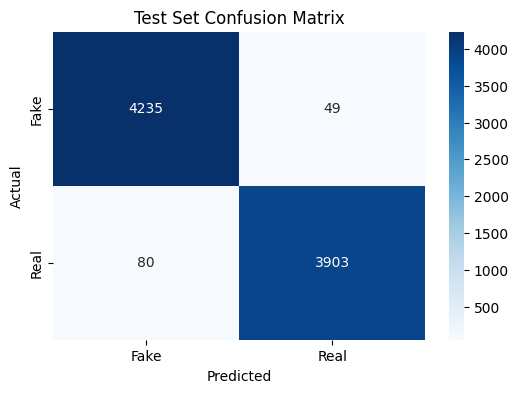

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
test_loss = 0.0
correct_test = 0
total_test = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * inputs.size(0)
        probabilities = F.softmax(outputs.data, dim=1)
        _, predicted = torch.max(probabilities, 1)

        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()


        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = test_loss / len(test_loader.dataset)
test_acc = 100 * correct_test / total_test

print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(all_labels, all_preds, target_names=['Fake (0)', 'Real (1)']))


cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Test Set Confusion Matrix')
plt.show()

In [17]:
import torch
import joblib

torch.save(model.state_dict(), "fake_news_model.pth")

joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model and Vectorizer saved successfully!")

Model and Vectorizer saved successfully!
